# 03 · Hybrid models, site adaptation and calibrated uncertainty

**Goal:** see exactly what the neural part of a hybrid model is allowed to learn, how a source-site model is adapted to a receiving site, and why an uncertainty band is only called *calibrated* when independent measured batches support it.

> **Every dataset in this notebook is SYNTHETIC.** Runs are generated by the same physical solvers with an authored "true" rate law and seeded noise. The results check that the code behaves correctly; they are **not** evidence of real-world accuracy, calibrated coverage, customer validation or workload savings.

This notebook uses the same backend modules as the product API and assistant (`process_engineering/hybrid.py`, `uncertainty.py`, `decisions.py`); there is no notebook-only implementation. Read [HYBRID_AND_UNCERTAINTY.md](HYBRID_AND_UNCERTAINTY.md) alongside it.

In [1]:
from pathlib import Path
import sys, json, math
from copy import deepcopy
import numpy as np
import matplotlib.pyplot as plt

root = next((p for p in [Path.cwd(), *Path.cwd().parents]
             if (p / "backend/src/lifesci/process_engineering/hybrid.py").exists()), None)
if root is None:
    raise RuntimeError("Open this notebook inside a BioDemo checkout that contains the model library")
sys.path.insert(0, str(root / "backend"))

from src.lifesci.ids import content_hash
from src.lifesci.chemical_reactor.model import validate
from src.lifesci.process_engineering.catalog import ModelCatalog
from src.lifesci.process_engineering import hybrid, uncertainty, decisions
from src.lifesci.process_engineering.contracts import contract
from src.lifesci.process_engineering.library_examples import synthetic_runs, interval_rows

catalog = ModelCatalog(None)
reactor = catalog.get("chemical.parallel_batch")
transport = catalog.get("fermentation.oxygen_transfer")
print(len(catalog.adapters), "registered models in the single existing catalogue")

22 registered models in the single existing catalogue


## 1. Which models may contain a learned term?

Hybrid learning is **opt-in per adapter**. A model supports it only when a reviewer has named the uncertain term, its units and its admissible range. Every other adapter reports that hybrid adaptation is unsupported; the library never attaches a generic neural correction to a model output.

In [2]:
for adapter in catalog.adapters.values():
    cap = hybrid.capabilities(adapter.id)
    status = "learns " + ", ".join(cap["terms"]) if cap["supported"] else "no hybrid term"
    print(f"{adapter.id:36s} {contract(adapter)['model_kind']:38s} {status}")
print()
print(json.dumps(hybrid.capabilities(reactor.id), indent=2))

lyo.kv_rp                            reduced_mechanistic                    no hybrid term
lyo.transient_lumped                 reduced_mechanistic                    no hybrid term
chemical.parallel_batch              reduced_mechanistic                    learns product_rate_multiplier, impurity_rate_multiplier
fermentation.oxygen_transfer         semimechanistic                        learns kla_multiplier
fermentation.pressure_cost           semimechanistic                        no hybrid term
chemical.semi_batch                  reduced_mechanistic                    no hybrid term
crystal.cooling_moments              reduced_mechanistic                    no hybrid term
isolation.cake_filter                reduced_mechanistic                    no hybrid term
isolation.cake_wash                  mechanistic_plus_screening_assumption  no hybrid term
isolation.cake_dryer                 semi_mechanistic                       no hybrid term
powder.continuous_blender            redu

## 2. What the physical model calculates

`chemical.parallel_batch` is a constant-volume batch reactor with a desired pathway $A\rightarrow B$ and an impurity pathway $A\rightarrow I$:

$$\frac{dN_A}{dt}=-(r_B+r_I),\quad \frac{dN_B}{dt}=r_B,\quad \frac{dN_I}{dt}=r_I,\qquad r_j = m_j\,k_j(T)\,N_A$$

$$\rho V c_p\frac{dT}{dt} = (-\Delta H_B)\,r_B + (-\Delta H_I)\,r_I - UA\,(T-T_c),\qquad k_j(T)=k_{j,\mathrm{ref}}\exp\!\left[-\frac{E_j}{R}\left(\frac1T-\frac1{T_\mathrm{ref}}\right)\right]$$

In the unchanged physical model the multipliers are $m_B=m_I=1$. In the hybrid model a small neural network supplies $m_B, m_I \in [0.25, 4]$ (dimensionless; the rates keep units of mol/s). The balances themselves never change, so $N_A+N_B+N_I$ is conserved whatever the network outputs, and the solver rejects any multiplier outside the bounds.

For `fermentation.oxygen_transfer` the existing model is **algebraic** oxygen-transfer and power scaling, not organism kinetics. Its hybrid term is one bounded $k_La$ multiplier. It cannot say anything about growth, titre or product quality.

Desired-product yield: 0.2635 | conversion: 0.3296 (conversion is NOT yield)
Largest A-equivalent mole-balance error: 7.105427357601002e-15


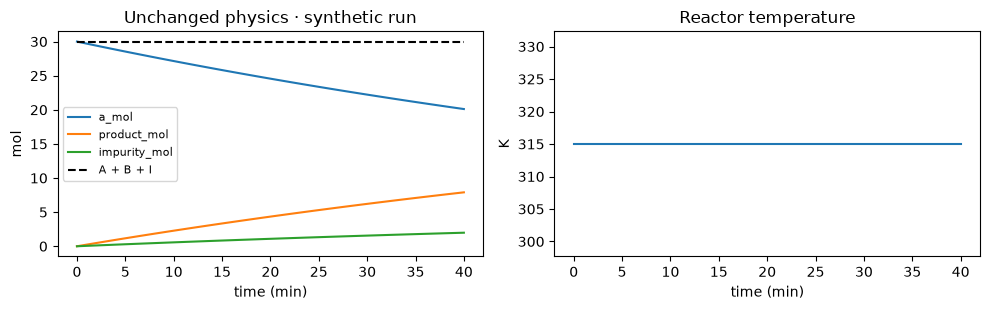

In [3]:
runs = synthetic_runs(reactor.id)
result = reactor.run(runs[0]["config"])
traj = result["trajectory"]
t = np.array([r["time_s"] for r in traj]) / 60
total = np.array([r["a_mol"] + r["product_mol"] + r["impurity_mol"] for r in traj])
print("Desired-product yield:", round(result["product_yield_fraction"], 4),
      "| conversion:", round(result["conversion_fraction"], 4), "(conversion is NOT yield)")
print("Largest A-equivalent mole-balance error:", result["maximum_a_equivalent_mole_error"])

fig, ax = plt.subplots(1, 2, figsize=(10, 3.2))
for field in ("a_mol", "product_mol", "impurity_mol"):
    ax[0].plot(t, [r[field] for r in traj], label=field)
ax[0].plot(t, total, "k--", label="A + B + I")
ax[0].set(xlabel="time (min)", ylabel="mol", title="Unchanged physics · synthetic run")
ax[0].legend(fontsize=8)
ax[1].plot(t, [r["temperature_k"] for r in traj])
ax[1].set(xlabel="time (min)", ylabel="K", title="Reactor temperature")
plt.tight_layout()

## 3. Partition whole batches before learning anything

Each synthetic run is one independent batch with an explicit role. All observations, time points and any augmented copies of a batch stay in that batch's role:

| Role | Used for |
|---|---|
| `train` | estimating rate multipliers and fitting network weights |
| `selection` | choosing regularisation and comparing physics / refit / hybrid |
| `calibration` | empirical interval calibration only |
| `test` | final evaluation only, after everything else is frozen |

Leakage is an error, not a warning. Time points and synthetic perturbations are never counted as extra independent batches.

In [4]:
roles = hybrid.partition(runs)
print({role: len(items) for role, items in roles.items()}, "batches per role")

leaked = deepcopy(runs)
leaked[-1]["batch_id"] = leaked[0]["batch_id"]          # a test run that shares a training batch
try:
    hybrid.partition(leaked)
except ValueError as exc:
    print("Rejected:", exc)

augmented = deepcopy(runs)
augmented[-1].update(augmented=True, origin_run_id=augmented[0]["run_id"])   # augmentation outside training
try:
    hybrid.partition(augmented)
except ValueError as exc:
    print("Rejected:", exc)

{'train': 8, 'selection': 3, 'calibration': 10, 'test': 3} batches per role
Rejected: Batch leakage between partitions
Rejected: Augmentation belongs to training original runs only


## 4. What the neural component learns

Training follows the two-stage idea of Al-Ramadhan et al. (DOI 10.1002/bit.70385), with documented departures:

1. **Estimate bounded, regularised state-dependent multipliers.** Between consecutive measurements, the integrated species balances give an interval-effective $m_B, m_I$. A bounded least-squares fit (range 0.25–4) with a smoothness penalty keeps them physically admissible.
2. **Learn their mapping.** A 6-unit tanh network with a scaled-sigmoid output maps *process state and characterised equipment* (temperature, remaining reactant fraction, area/volume, heat-transfer coefficient, coolant temperature) to the multipliers. Site names, run IDs, time and future observations are never inputs.
3. **Embed the network in the solver** and compare it on the selection batches against unchanged physics and an ordinary constant-multiplier refit.

Every checkpoint records its training/selection batches, seed, data-partition hash and the departures from the paper.

In [5]:
checkpoint = hybrid.train(reactor, runs, ensemble_size=3)
print("Network inputs:", checkpoint["features"])
print("Selected on selection batches:", checkpoint["selected_model"])
for mode, score in checkpoint["selection"].items():
    print(f"  {mode:8s} scaled RMSE {score['rmse_scaled']:.5f}   failed {score['failed_predictions']}")
print("Classification:", checkpoint["classification"])
print("Departures from the paper:")
for item in checkpoint["methodological_departures"]:
    print("  -", item)

Network inputs: ['temperature_k', 'reactant_fraction', 'area_per_volume_m_inv', 'heat_transfer_w_m2_k', 'coolant_temperature_k']
Selected on selection batches: hybrid
  physics  scaled RMSE 0.08880   failed 0
  refit    scaled RMSE 0.00563   failed 0
  hybrid   scaled RMSE 0.00027   failed 0
Classification: synthetic_development_only
Departures from the paper:
  - Chemical estimation uses integrated species balances with measured temperatures, not full nonlinear TVP trajectory optimization.
  - Transport adapter learns algebraic kLa factors, not fermentation organism kinetics.
  - Six hidden units, smooth L1 source-weight regularization, whole-batch bootstrap; no paper-results reproduction claim.


The authored synthetic "truth" is $m_B = 1.4 + 0.5\,a + 0.0005\,U$ and $m_I = 0.7 + 0.7\,(1-a)$, where $a$ is the remaining reactant fraction. The plot shows what one ensemble member learned at the source equipment ($U = 200$ W m⁻² K⁻¹). It should follow the truth inside the training support. That only shows the code can recover a known rate law, not that a real reaction behaves this way.

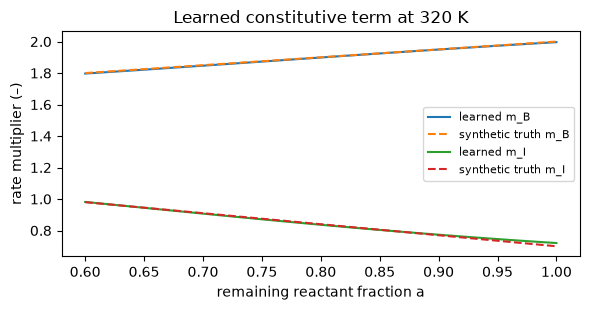

In [6]:
cfg = validate(runs[0]["config"])
n0 = cfg.recipe.initial_a_mol_m3 * cfg.equipment.working_volume_m3
fractions = np.linspace(0.6, 1.0, 30)
learned = np.array([hybrid.factors(checkpoint["members"][0],
                    hybrid.chemistry_features([a * n0, 0, 0, 320.0], cfg))[0] for a in fractions])
fig, ax = plt.subplots(figsize=(6, 3.2))
ax.plot(fractions, learned[:, 0], label="learned m_B")
ax.plot(fractions, 1.4 + 0.5 * fractions + 0.0005 * 200, "--", label="synthetic truth m_B")
ax.plot(fractions, learned[:, 1], label="learned m_I")
ax.plot(fractions, 0.7 + 0.7 * (1 - fractions), "--", label="synthetic truth m_I")
ax.set(xlabel="remaining reactant fraction a", ylabel="rate multiplier (–)", title="Learned constitutive term at 320 K")
ax.legend(fontsize=8); plt.tight_layout()

### Conservation and bounds hold with the learned term in place

In [7]:
hybrid_run = hybrid.run_hybrid(reactor, runs[0]["config"], checkpoint)
h = hybrid_run["trajectory"]
drift = max(abs(r["a_mol"] + r["product_mol"] + r["impurity_mol"] - (h[0]["a_mol"] + h[0]["product_mol"] + h[0]["impurity_mol"])) for r in h)
print("Max drift in A + B + I (mol):", drift)
print("Hybrid status:", hybrid_run["hybrid"]["status"], "| risk probability:", hybrid_run["hybrid"]["risk_probability"])

Max drift in A + B + I (mol): 2.4868995751603507e-14
Hybrid status: within_observed_feature_support | risk probability: None


## 5. Final test: physics vs ordinary refit vs hybrid

The test batches were not used for weights, regularisation or model choice. On this synthetic study the hybrid should win, because the synthetic truth *is* a state-dependent multiplier. On real data that is a hypothesis to test, and a simple refit may be the better choice.

In [8]:
for mode in ("physics", "refit", "hybrid"):
    s = hybrid.score(reactor, roles["test"], checkpoint, mode)
    print(f"{mode:8s} scaled RMSE {s['rmse_scaled']:.5f}  failed {s['failed_predictions']}  out-of-domain {s['out_of_domain_runs']}  of {s['runs']} test batches")

physics  scaled RMSE 0.08661  failed 0  out-of-domain 0  of 3 test batches
refit    scaled RMSE 0.00569  failed 0  out-of-domain 0  of 3 test batches
hybrid   scaled RMSE 0.00024  failed 0  out-of-domain 0  of 3 test batches


## 6. Source-to-receiver adaptation and negative transfer

The receiving site has different jacket performance ($U = 300$ instead of 200). The source network has never seen that equipment, so it flags the receiver runs as **out of domain** and withholds calibrated claims.

Adaptation starts from the source weights and penalises distance from them (smooth L1, penalty 0.01). It fits only receiver training batches and selects using receiver selection batches. The adapted checkpoint is a **new** artifact that points to the immutable source by hash. If the adapted model is worse than the source, physics or refit alternatives on the selection batches, it is marked as negative transfer and its use is blocked.

In [9]:
receiver_runs = synthetic_runs(reactor.id, seed=44, receiver=True)
receiver_roles = hybrid.partition(receiver_runs)
source_on_receiver = hybrid.score(reactor, receiver_roles["selection"], checkpoint, "hybrid")
print("Source model on receiver selection batches: out-of-domain", source_on_receiver["out_of_domain_runs"], "of", source_on_receiver["runs"])

adapted = hybrid.train(reactor, receiver_runs, parent=checkpoint, ensemble_size=3)
print("Source checkpoint hash:          ", content_hash(checkpoint)[:16])
print("Adapted checkpoint's source hash:", adapted["source_checkpoint_hash"][:16], "(source is unchanged and stored separately)")
for mode, score in adapted["selection"].items():
    print(f"  {mode:8s} scaled RMSE {score['rmse_scaled']:.5f}  out-of-domain {score['out_of_domain_runs']}")
print("Negative transfer:", adapted["negative_transfer"], "→ promotion:", adapted["promotion"])
print("Rule:", adapted["negative_transfer_rule"])

Source model on receiver selection batches: out-of-domain 3 of 3
Source checkpoint hash:           1641ef555e85d930
Adapted checkpoint's source hash: 1641ef555e85d930 (source is unchanged and stored separately)
  physics  scaled RMSE 0.08800  out-of-domain 0
  refit    scaled RMSE 0.00627  out-of-domain 0
  hybrid   scaled RMSE 0.00030  out-of-domain 0
  source   scaled RMSE 0.00794  out-of-domain 3
Negative transfer: False → promotion: draft_requires_review
Rule: Adapted hybrid selection RMSE exceeds the best source/physics/refit alternative by >1% plus 1e-8; heuristic, not a significance test.


The same procedure on the fermentation transport adapter shows the guard firing. With only four receiver training batches, the adapted $k_La$ correction does worse than the unadapted source model on the receiver selection batches, so it is withheld.

In [10]:
oxygen_source = hybrid.train(transport, synthetic_runs(transport.id), ensemble_size=2)
oxygen_adapted = hybrid.train(transport, synthetic_runs(transport.id, seed=44, receiver=True), parent=oxygen_source, ensemble_size=2)
for mode, score in oxygen_adapted["selection"].items():
    print(f"  {mode:8s} scaled RMSE {score['rmse_scaled']:.5f}")
print("Negative transfer:", oxygen_adapted["negative_transfer"], "→ promotion:", oxygen_adapted["promotion"])

  physics  scaled RMSE 0.19317
  refit    scaled RMSE 0.04633
  hybrid   scaled RMSE 0.00163
  source   scaled RMSE 0.00126
Negative transfer: True → promotion: withheld_negative_transfer


## 7. Uncertainty: four different things

| Source | How it is represented | Calibrated? |
|---|---|---|
| Measurement | declared `measurement_std` added to the predicted observable | no, only declared |
| Parameter | declared distributions on adapter inputs, propagated through the solver | no, only declared |
| Learned model | spread across whole-batch bootstrap network members, each run through the solver | no, ensemble spread only |
| Structural discrepancy / unsupported conditions | not quantified; out-of-domain inputs cause abstention | never |

An ensemble band is labelled `NOT calibrated` and carries `calibration_status: uncalibrated` and `risk_probability: None`.

In [11]:
observations = interval_rows(runs[0])
band = uncertainty.ensemble(reactor, runs[0]["config"], observations, checkpoint=checkpoint, mode="hybrid", samples=6,
    distributions=[{"category": "parameter", "path": "chemistry.product_rate_ref_s_inv", "unit": "1/s", "std": 1e-5}])
print("Observable:", band["basis"])
print("Mean", np.round(band["mean"], 3), "| 10–90% band", np.round(band["lower"], 3), "–", np.round(band["upper"], 3))
print(band["ensemble_band"], "| calibration:", band["calibration_status"], "| risk probability:", band["risk_probability"])
print("Structural discrepancy:", band["uncertainty_components"]["structural_discrepancy"])

ood = deepcopy(runs[0]["config"]); ood["equipment"]["heat_transfer_coefficient_w_m2_k"] = 1000.0
ood_band = uncertainty.ensemble(reactor, ood, observations, checkpoint=checkpoint, mode="hybrid", samples=2)
print("Unsupported equipment (U = 1000): abstention =", ood_band["abstention"], "| risk probability:", ood_band["risk_probability"])

Observable: [('product_mol', 'mol', 2400.0)]
Mean [13.209] | 10–90% band [12.912] – [13.446]
10th..90th sample quantiles, NOT calibrated intervals | calibration: uncalibrated | risk probability: None
Structural discrepancy: not quantified; ensemble cannot identify omitted physical mechanisms
Unsupported equipment (U = 1000): abstention = True | risk probability: None


## 8. Interval calibration is a separate layer

`calibrate_intervals` applies split-conformal calibration to **whole independent calibration batches**:

1. For each calibration batch, compute the ensemble band and the score $s_i = \max_k \max(\ell_k - y_k,\; y_k - u_k,\; 0)/\text{scale}_k$, the worst normalised miss over the batch's prediction grid.
2. With $n$ batches and target miscoverage $\alpha$, take $q = s_{(\lceil (n+1)(1-\alpha)\rceil)}$, the order statistic.
3. Widen future bands by $q \cdot \text{scale}$.

**Assumptions behind any coverage statement:** calibration and future batches are independent and exchangeable, on the same measurement basis and operating population, with no failed or out-of-domain predictions silently dropped. The guarantee is marginal over batches, not conditional on a particular batch.

The library returns `uncalibrated` unless at least 9 eligible batches exist, and only *measured* or *published experimental* runs with a stated independence basis are eligible. Our synthetic runs therefore stay uncalibrated:

In [12]:
calibration_runs = deepcopy(roles["calibration"]); test_runs = deepcopy(roles["test"])
for r in calibration_runs + test_runs:
    r["observations"] = interval_rows(r)
library_calibration = uncertainty.calibrate_intervals(reactor, calibration_runs, checkpoint=checkpoint, mode="hybrid", samples=3)
print("Status:", library_calibration["status"], "| eligible independent batches:", library_calibration["independent_calibration_groups"])
print("Reason:", library_calibration["reason"])
evaluation = uncertainty.evaluate_intervals(reactor, test_runs, library_calibration, checkpoint=checkpoint)
print("Test batches scored for coverage:", evaluation["scored_coverage_batches"], "| abstentions:", evaluation["abstentions"])

Status: uncalibrated | eligible independent batches: 0
Reason: Insufficient original independently supported measured batches, or unsupported/failed predictions
Test batches scored for coverage: 0 | abstentions: 3


### Walk-through of the arithmetic, done by hand (SYNTHETIC, not a coverage claim)

To see what the calibration layer would compute with eligible data, the cell below repeats the steps by hand on the synthetic calibration and test batches. It deliberately does **not** create a calibration record, and the number it prints says nothing about real-world coverage.

In [13]:
alpha, scores = 0.1, []
for r in calibration_runs:
    b = uncertainty.ensemble(reactor, r["config"], r["observations"], checkpoint=checkpoint, mode="hybrid", samples=3)
    y = np.array([o["value"] for o in r["observations"]]); scale = np.array([o["scale"] for o in r["observations"]])
    scores.append(float(np.max(np.maximum.reduce([np.array(b["lower"]) - y, y - np.array(b["upper"]), np.zeros_like(y)]) / scale)))
n = len(scores); k = math.ceil((n + 1) * (1 - alpha)); q = sorted(scores)[k - 1]
print(f"n = {n} calibration batches, order statistic k = {k}, q = {q:.5f}")
covered = []
for r in test_runs:
    b = uncertainty.ensemble(reactor, r["config"], r["observations"], checkpoint=checkpoint, mode="hybrid", samples=3)
    y = np.array([o["value"] for o in r["observations"]]); scale = np.array([o["scale"] for o in r["observations"]])
    covered.append(bool(np.all((np.array(b["lower"]) - q * scale <= y) & (y <= np.array(b["upper"]) + q * scale))))
print(f"Synthetic test batches inside widened band: {sum(covered)} of {len(covered)} (3 batches cannot estimate coverage)")

n = 10 calibration batches, order statistic k = 10, q = 0.00043
Synthetic test batches inside widened band: 2 of 3 (3 batches cannot estimate coverage)


## 9. From predictions to transfer decisions

Acceptance criteria are explicit: metric, unit, measurement basis, operator (`>=` when higher is better, `<=` when lower is better) and limit. The library:

- refuses to use **conversion** as desired-product yield;
- **withholds** a conclusion when the model does not predict a required quality attribute;
- gives a verdict only from a **calibrated range**: `conditional_pass` when the whole receiver range clears the limit, `fails_criterion` when it is entirely on the wrong side, `inconclusive` when it straddles the limit;
- marks everything else `indicative_only`: no calibration (as below), synthetic-only calibration, or a receiver outside the calibrated operating range. A single model estimate is never a pass or a fail;
- for **noninferiority**, uses the difference of the donor and receiver calibrated ranges (a non-significant difference is never accepted as proof).

In [14]:
donor = reactor.run(runs[0]["config"]); receiver = reactor.run(receiver_runs[0]["config"])
criteria = [
    {"metric": "product_yield_fraction", "unit": "fraction", "basis": "desired_product_mol_per_initial_reactant_mol",
     "role": "yield", "operator": ">=", "limit": 0.2},
    {"metric": "impurity_fraction", "unit": "fraction", "basis": "impurity_mol_per_initial_reactant_mol",
     "role": "quality", "operator": "<=", "limit": 0.08},
    {"metric": "particle_size_d50_um", "unit": "um", "basis": "laser_diffraction_volume_median",
     "role": "quality", "operator": "<=", "limit": 150.0},
]
assessment = decisions.transfer_assessment(reactor, donor, receiver, criteria)
for check in assessment["checks"]:
    print(f"{check['metric']:24s} {check['status']:18s} {check.get('reason', '')}")
print("Conclusion:", assessment["conclusion"], "|", assessment["authorization"])

noninferiority = [{**criteria[0], "method": "noninferiority", "margin": 0.02}]
check = decisions.transfer_assessment(reactor, donor, receiver, noninferiority)["checks"][0]
print("Noninferiority:", check["status"], "|", check["reason"])
try:
    decisions.transfer_assessment(reactor, donor, receiver, [{**criteria[0], "metric": "conversion_fraction", "basis": "charged reactant"}])
except ValueError as exc:
    print("Rejected:", exc)

product_yield_fraction   indicative_only    No interval calibration attached; a single model estimate cannot pass or fail a criterion
impurity_fraction        indicative_only    No interval calibration attached; a single model estimate cannot pass or fail a criterion
particle_size_d50_um     withheld           Model does not predict this required quality attribute on the requested unit/basis
Conclusion: withheld_missing_quality_evidence | draft_requires_engineering_review
Noninferiority: indicative_only | No interval calibration attached; a single model estimate cannot pass or fail a criterion
Rejected: Reactant conversion cannot serve as desired-product yield


### Rank characterisation experiments for that decision

Candidate experiments are scored by whether the model's spread at those conditions straddles the decision threshold, relative to measurement resolution and stated cost. This is a transparent heuristic, **not** expected information gain. Infeasible or out-of-domain candidates are rejected with a reason.

In [15]:
base = runs[0]["config"]
spread = [{"category": "parameter", "path": "chemistry.product_rate_ref_s_inv", "unit": "1/s", "std": 2e-5}]
endpoint = [{"coordinate": 2400.0, "observable": "product_mol", "unit": "mol", "value": 0.0}]
nominal = uncertainty.ensemble(reactor, base, endpoint, samples=3, distributions=spread)
# A threshold inside the modelled spread is where a measurement can change the decision.
threshold = float(np.median([p[0] for p in nominal["predictions"]]))
print(f"Decision: is product at 40 min >= {threshold:.2f} mol?")
decision = {"observable": "product_mol", "unit": "mol", "coordinate": 2400.0, "threshold": threshold, "distributions": spread}
candidates = [
    {"measurement": "Product assay at 40 min, nominal temperature", "measurement_resolution": 0.5, "cost": 1.0,
     "conditions": {"recipe.initial_temperature_k": base["recipe"]["initial_temperature_k"]}},
    {"measurement": "Product assay at 40 min, +10 K", "measurement_resolution": 0.5, "cost": 1.0,
     "conditions": {"recipe.initial_temperature_k": base["recipe"]["initial_temperature_k"] + 10, "equipment.coolant_temperature_k": base["recipe"]["initial_temperature_k"] + 10}},
    {"measurement": "Product assay at 40 min, 700 K (outside model limits)", "measurement_resolution": 0.5, "cost": 1.0,
     "conditions": {"recipe.initial_temperature_k": 700.0}},
]
ranking = decisions.rank_experiments(reactor, base, candidates, decision)
for item in ranking["ranked"]:
    print(f"{item['utility_proxy']:.3f}  straddles threshold: {item['threshold_straddled']!s:5s}  {item['measurement']}")
for item in ranking["rejected"]:
    print("rejected:", item["candidate"]["measurement"], "→", item["reason"][:90])
print(ranking["ranked"][0]["limitations"])

Decision: is product at 40 min >= 8.21 mol?
0.501  straddles threshold: True   Product assay at 40 min, nominal temperature
0.053  straddles threshold: False  Product assay at 40 min, +10 K
rejected: Product assay at 40 min, 700 K (outside model limits) → outside declared model applicability
Heuristic decision-discrimination proxy; not calibrated expected information gain, intervention benefit or validated experiment feasibility.


## 10. A missing mechanism becomes a proposal, not an equation change

If residuals point at chemistry the model does not contain, such as a third pathway, the right response is a reviewable **model-extension proposal**, never a silent change to the equations or an unrestricted neural residual. The proposal goes through the existing approval service. It records the current model version and digest, and leaves the registered model, its checkpoints and its calibrations untouched.

The cell uses an in-memory platform with the same services as the product API.

In [16]:
from src.lifesci.container import Platform
from src.lifesci.store import RecordStore

platform = Platform(RecordStore(), providers={})
platform.identity.assign_role("demo", "engineer", "msat", site_id="NF1")
ctx = platform.identity.context_for("demo", "engineer")
service = platform.process_models.analysis
packet = {"config": runs[0]["config"]}
evidence = platform.evidence.ingest(ctx, source_system="notebook-synthetic", source_record_id="reactor-study",
    content=json.dumps(packet, sort_keys=True).encode(), media_type="application/json", site_id="NF1",
    event_time=None, metadata={"classification": "synthetic_development"})
basis = {"kind": "evidence", "id": evidence["evidence_id"], "revision": evidence["revision"], "site_id": "NF1"}
context = service.create_configuration(ctx, {"model_id": reactor.id, "site_id": "NF1", "label": "SYNTHETIC reactor study",
    "config": runs[0]["config"], "basis": [basis], "classification": "synthetic_assumption"})
proposal = service.propose_model_extension(ctx, {
    "context_id": context["id"], "model_id": reactor.id, "basis": [basis],
    "mechanism_change": "Add a consecutive over-reaction B -> I2 suggested by late-time product loss in receiver assays.",
    "affected_equations": "dN_B/dt = r_B - r_2; dN_I2/dt = r_2; r_2 = k_2(T) N_B; energy balance gains (-dH_2) r_2.",
    "new_parameters": [{"name": "over_reaction_rate_ref_s_inv", "unit": "1/s", "lower_bound": 0.0, "upper_bound": 1e-3,
                        "identifying_measurement": "Time-resolved B and I2 assays at two temperatures"}],
    "conservation_impact": "A + B + I + I2 remains equal to the initial A; no new inflow or outflow.",
    "limiting_case": "With over_reaction_rate_ref_s_inv = 0 the extended model equals the current parallel-batch model.",
    "verification_plan": "Mole-closure and zero-rate equivalence tests, then held-out time-resolved assays.",
    "owner_id": "engineer"})
print(proposal["operation"], "|", proposal["status"], "| registry:", proposal["payload"]["registry_status"],
      "| execution permission:", proposal["payload"]["execution_permission"])
print("Current digest recorded:", proposal["payload"]["current_model"]["implementation_digest"][:16],
      "== live digest:", reactor.digest[:16])
platform.runtime.close(); platform.store.release_connections()

review_model_extension | proposed | registry: unchanged | execution permission: none
Current digest recorded: 74dc018db17ca853 == live digest: 74dc018db17ca853


## 11. What is implemented, experimental or unvalidated

| Capability | Status |
|---|---|
| Bounded learned rate multipliers inside the reactor balances | Implemented; synthetic checks only |
| Bounded learned $k_La$ multiplier in oxygen-transfer algebra | Implemented; synthetic checks only; no organism kinetics |
| Hybrid terms for the other 20 adapters | Unsupported by design |
| Source-to-receiver adaptation, separate checkpoints, negative-transfer block | Implemented; the rule is a heuristic threshold, not a significance test |
| Solver-propagated ensembles (measurement, parameter, learned) | Implemented; spread is not calibrated |
| Split-conformal interval calibration and held-out evaluation | Implemented; **never yet run on eligible measured data** |
| Real-world accuracy or calibrated coverage for any customer process | **Not established** |

## Your tasks

1. Halve the number of training batches (`synthetic_runs` roles). Does the selection step still prefer the hybrid over the refit?
2. Change the synthetic truth so $m_B$ is constant. Which model should now win, and does it?
3. Move one calibration batch into `test` with the same `batch_id`. Read the error message.
4. Explain in three sentences why 17 time points in one batch are not 17 calibration samples.
5. Write the criteria you would need before stating that receiver yield is noninferior.